# Diabetes Risk Screening Tool
**NextGen Institute · Machine Learning · Final Project (Idea #11 — Healthcare · Public Health)**

**Author:** Abdelrhman Sherif Mekkawy

A model that flags people who should get a proper diabetes test, based on 8 simple clinic measurements, deployed as a Streamlit app.

## 1 · Problem framing
- **Who has the problem?** A clinic or public-health program that wants to screen many people cheaply and send the risky ones for a confirmatory lab test.
- **Decision the model supports:** *"Should this person be referred for a diabetes test?"*
- **Target:** `Outcome` — 1 = diabetes, 0 = no diabetes (binary classification).
- **Metric that matters:** **Recall on the diabetic class** (don't miss sick people), watched together with precision and ROC-AUC. Missing a diabetic person (false negative) is worse than sending a healthy person for an extra test (false positive), so **accuracy alone is misleading** and we tune the decision threshold for recall.

In [1]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     GridSearchCV, cross_val_predict)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (confusion_matrix, classification_report, roc_auc_score,
                             roc_curve, ConfusionMatrixDisplay, precision_recall_curve,
                             recall_score, precision_score, f1_score, accuracy_score)
from sklearn.inspection import permutation_importance
from utils import zeros_to_nan, FEATURES, ZERO_AS_MISSING

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
os.makedirs("images", exist_ok=True)

## 2 · Data understanding
**Source:** Pima Indians Diabetes Database (National Institute of Diabetes and Digestive and Kidney Diseases, hosted on UCI / Kaggle). The CSV copy used here is from the [plotly/datasets repo](https://github.com/plotly/datasets/blob/master/diabetes.csv). Women of Pima Indian heritage, aged 21+.

| Column | Meaning |
|---|---|
| Pregnancies | Number of times pregnant |
| Glucose | Plasma glucose concentration (2 h oral glucose tolerance test) |
| BloodPressure | Diastolic blood pressure (mm Hg) |
| SkinThickness | Triceps skin-fold thickness (mm) |
| Insulin | 2-hour serum insulin (mu U/ml) |
| BMI | Body mass index (kg/m²) |
| DiabetesPedigreeFunction | Diabetes family-history score |
| Age | Age in years |
| **Outcome** | **Target: 1 = diabetes, 0 = not** |

In [2]:
df = pd.read_csv("data/diabetes.csv")
print("Shape:", df.shape)
display(df.head())
display(df.dtypes.to_frame("dtype").T)
print("Real NaNs per column:", df.isna().sum().sum())

Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
dtype,int64,int64,int64,int64,int64,float64,float64,int64,int64


Real NaNs per column: 0


In [3]:
# Class balance
bal = df["Outcome"].value_counts().rename({0: "No diabetes", 1: "Diabetes"})
display(pd.DataFrame({"count": bal, "share": (bal / len(df)).round(3)}))

# Hidden missing values: impossible zeros
zeros = (df[ZERO_AS_MISSING] == 0).sum().to_frame("zeros")
zeros["share"] = (zeros["zeros"] / len(df)).round(3)
display(zeros)

,count,share
Outcome,,
No diabetes,500,0.651
Diabetes,268,0.349


,zeros,share
Glucose,5,0.007
BloodPressure,35,0.046
SkinThickness,227,0.296
Insulin,374,0.487
BMI,11,0.014


**Data-quality finding:** there are no real NaNs, but columns such as `Insulin` and `SkinThickness` contain many `0`s. A person cannot have 0 BMI or 0 glucose, so these zeros are **disguised missing values**. We convert them to `NaN` and impute inside the pipeline (so imputation statistics come from training data only).

## 3 · Exploratory Data Analysis

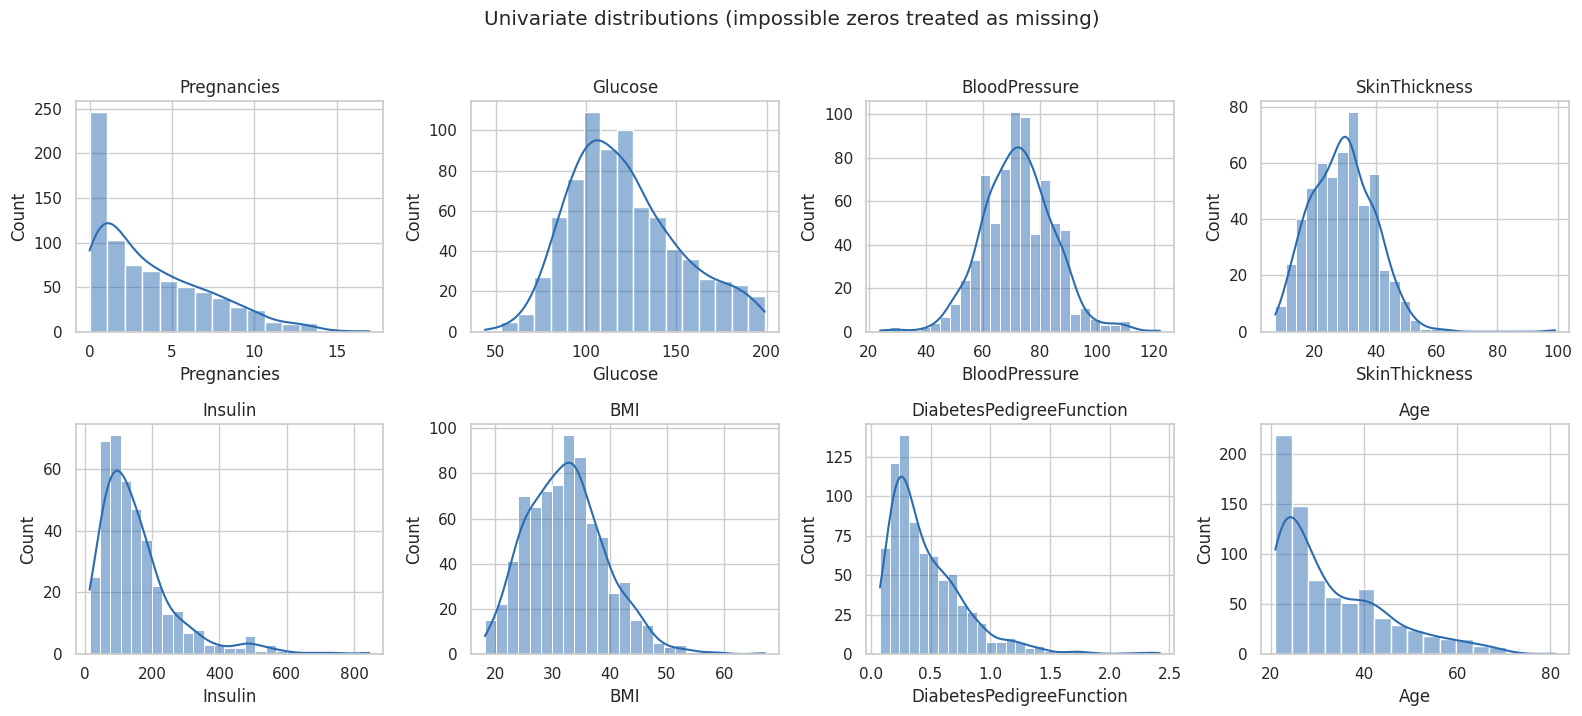

In [4]:
# Univariate: distribution of every feature
df_clean = df.copy()
df_clean[ZERO_AS_MISSING] = df_clean[ZERO_AS_MISSING].replace(0, np.nan)
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.histplot(df_clean[col].dropna(), kde=True, ax=ax, color="#2b6cb0")
    ax.set_title(col)
plt.suptitle("Univariate distributions (impossible zeros treated as missing)", y=1.02)
plt.tight_layout(); plt.show()

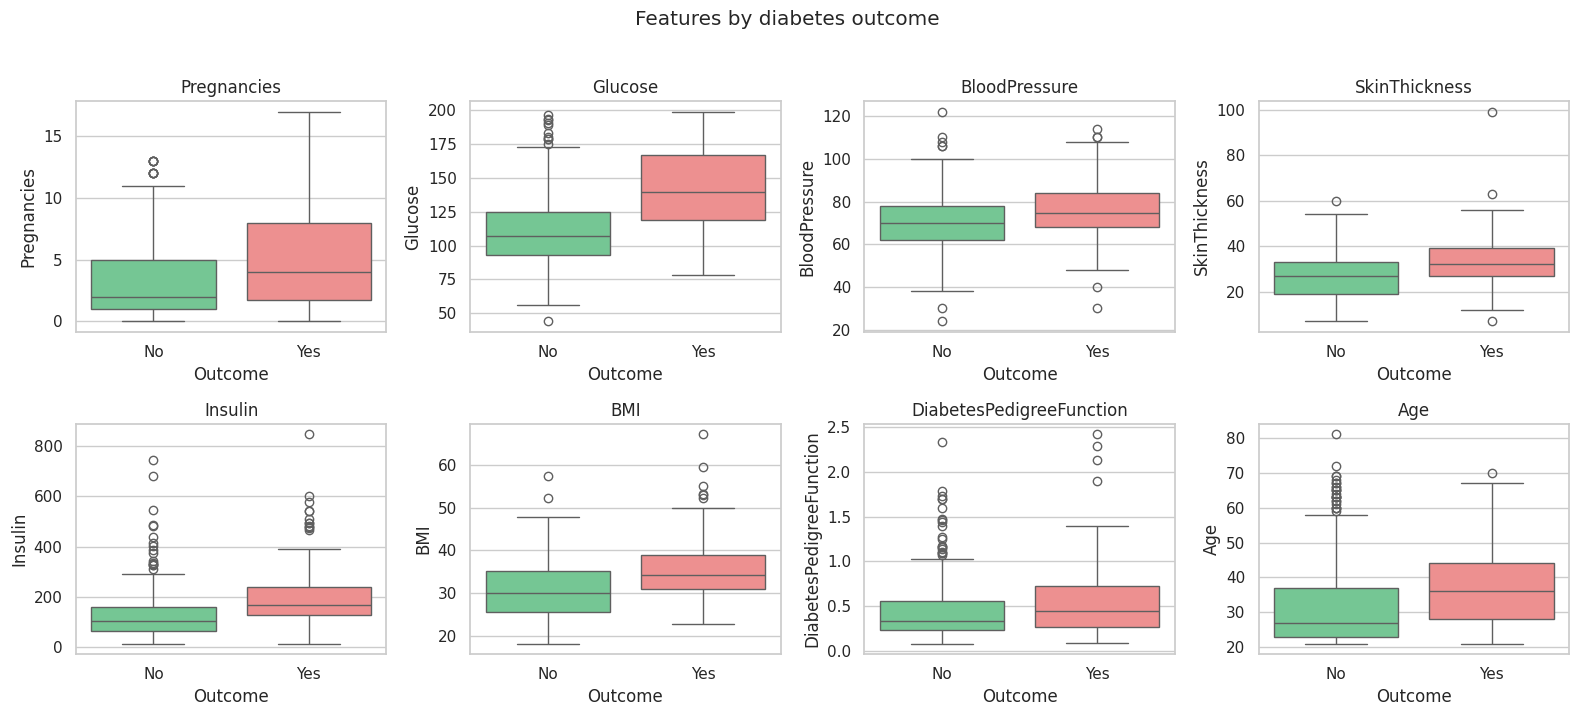

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
Outcome,,,,,,,,
0,2.0,107.0,70.0,27.0,102.5,30.1,0.3,27.0
1,4.0,140.0,74.5,32.0,169.5,34.3,0.4,36.0


In [5]:
# Bivariate: each feature vs. outcome
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.boxplot(data=df_clean, x="Outcome", y=col, ax=ax, palette=["#68d391", "#fc8181"])
    ax.set_xticklabels(["No", "Yes"]); ax.set_title(col)
plt.suptitle("Features by diabetes outcome", y=1.02)
plt.tight_layout(); plt.savefig("images/eda_boxplots.png", dpi=120, bbox_inches="tight"); plt.show()

display(df_clean.groupby("Outcome")[FEATURES].median().round(1))

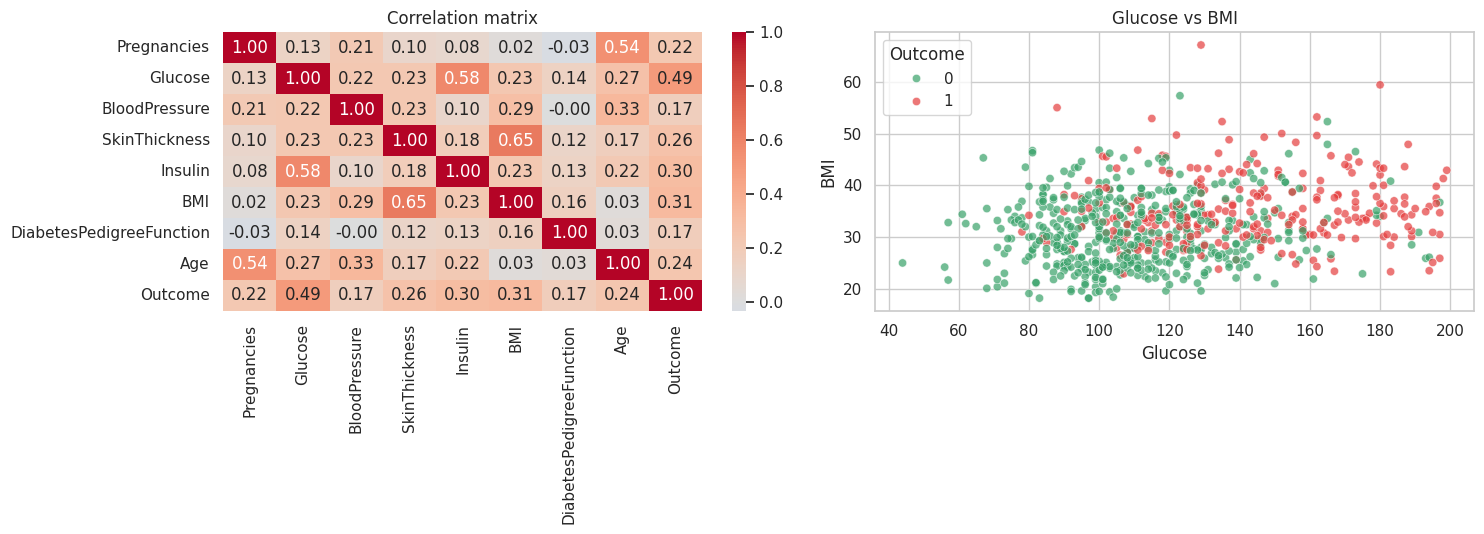

,corr with Outcome
Glucose,0.49
BMI,0.31
Insulin,0.30
SkinThickness,0.26
Age,0.24
Pregnancies,0.22
DiabetesPedigreeFunction,0.17
BloodPressure,0.17


In [6]:
# Multivariate: correlations and a Glucose x BMI view
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(df_clean.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Correlation matrix")
sns.scatterplot(data=df_clean, x="Glucose", y="BMI", hue="Outcome",
                palette={0: "#38a169", 1: "#e53e3e"}, alpha=.7, ax=axes[1])
axes[1].set_title("Glucose vs BMI")
plt.tight_layout(); plt.savefig("images/eda_corr.png", dpi=120, bbox_inches="tight"); plt.show()
display(df_clean.corr()["Outcome"].drop("Outcome").sort_values(ascending=False).round(2).to_frame("corr with Outcome"))

### Key EDA insights / hypotheses
1. **Glucose is the strongest single signal** — correlation with the outcome is 0.49, and the median glucose is 140 for diabetic vs 107 for non-diabetic people.
2. **Body weight and age matter, but less.** BMI (0.31), Insulin (0.30), SkinThickness (0.26), Age (0.24) and Pregnancies (0.22) are moderately correlated; diabetic patients are older (median 36 vs 27) and have had more pregnancies (median 4 vs 2).
3. **Data quality is a real issue:** about 49% of `Insulin` and 30% of `SkinThickness` values are impossible zeros (missing measurements). How we impute them will affect the model, and we add a missing-value indicator so the model can use "was not measured" as a signal.
4. **The classes are imbalanced (35% diabetic):** a model that always predicts "no diabetes" gets about 65% accuracy while catching nobody, so accuracy is the wrong yardstick and recall must be tracked.
5. **Hypothesis:** the boxplots overlap heavily for every feature, so no single feature separates the classes cleanly. We expect a linear/simple model on all features to reach a ROC-AUC around 0.8 to 0.85, not much higher.

## 4 · Train / test split & preprocessing pipeline
We **split first** (stratified 80/20) and put every preprocessing step inside a scikit-learn `Pipeline`, so imputation and scaling are learned on training folds only → **no data leakage**. The test set is not touched until the final evaluation.

In [7]:
X = df[FEATURES]
y = df["Outcome"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Positive rate  train: %.3f  test: %.3f" % (y_train.mean(), y_test.mean()))

def make_pipe(model):
    return Pipeline([
        ("zeros_to_nan", FunctionTransformer(zeros_to_nan)),
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
        ("model", model),
    ])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Train: (614, 8) | Test: (154, 8)
Positive rate  train: 0.349  test: 0.351


## 5 · Modeling: baseline + 3 algorithms (5-fold cross-validation on the training set)

In [8]:
models = {
    "Baseline (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}
rows = []
for name, m in models.items():
    r = cross_validate(make_pipe(m), X_train, y_train, cv=cv,
                       scoring=["accuracy", "recall", "precision", "f1", "roc_auc"])
    rows.append({"model": name, **{k.replace("test_", ""): v.mean() for k, v in r.items() if k.startswith("test_")}})
cv_table = pd.DataFrame(rows).set_index("model").round(3)
cv_table

,accuracy,recall,precision,f1,roc_auc
model,,,,,
Baseline (most frequent),0.651,0.000,0.000,0.000,0.500
Logistic Regression,0.775,0.734,0.662,0.695,0.839
Random Forest,0.774,0.589,0.719,0.645,0.827
Gradient Boosting,0.759,0.607,0.675,0.637,0.823


## 6 · Hyperparameter tuning (grid search, training data only, optimizing ROC-AUC)

In [9]:
grids = {
    "Logistic Regression": (LogisticRegression(max_iter=2000, class_weight="balanced"),
                            {"model__C": [0.01, 0.1, 1, 10], "model__penalty": ["l2"]}),
    "Random Forest": (RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE),
                      {"model__n_estimators": [200, 400], "model__max_depth": [3, 5, 8],
                       "model__min_samples_leaf": [3, 8]}),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=RANDOM_STATE),
                          {"model__n_estimators": [100, 200], "model__learning_rate": [0.03, 0.1],
                           "model__max_depth": [2, 3]}),
}
tuned, rows = {}, []
for name, (m, grid) in grids.items():
    gs = GridSearchCV(make_pipe(m), grid, cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)
    tuned[name] = gs.best_estimator_
    rows.append({"model": name, "best CV ROC-AUC": round(gs.best_score_, 3), "best params": gs.best_params_})
pd.DataFrame(rows).set_index("model")

,best CV ROC-AUC,best params
model,,
Logistic Regression,0.841,"{'model__C': 0.1, 'model__penalty': 'l2'}"
Random Forest,0.837,"{'model__max_depth': 5, 'model__min_samples_le..."
Gradient Boosting,0.827,"{'model__learning_rate': 0.03, 'model__max_dep..."


In [10]:
best_name = max(rows, key=lambda r: r["best CV ROC-AUC"])["model"]
best_pipe = tuned[best_name]
print("Selected model (by CV ROC-AUC on training data):", best_name)

# Choose the decision threshold from CROSS-VALIDATED training probabilities only:
# the highest threshold that still catches >= 80% of diabetic cases (best precision at that recall).
TARGET_RECALL = 0.80
oof = cross_val_predict(best_pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
ok = np.where(rec[:-1] >= TARGET_RECALL)[0]
THRESHOLD = float(thr[ok[-1]])
print(f"Chosen threshold: {THRESHOLD:.3f}  (CV recall {rec[ok[-1]]:.3f}, CV precision {prec[ok[-1]]:.3f})")

Selected model (by CV ROC-AUC on training data): Logistic Regression
Chosen threshold: 0.430  (CV recall 0.804, CV precision 0.595)


## 7 · Final evaluation on the untouched test set

In [11]:
base = make_pipe(DummyClassifier(strategy="most_frequent")).fit(X_train, y_train)
proba = best_pipe.predict_proba(X_test)[:, 1]

def scores(y_true, pred, p=None):
    return {"accuracy": accuracy_score(y_true, pred), "recall": recall_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0),
            "f1": f1_score(y_true, pred), "roc_auc": roc_auc_score(y_true, p) if p is not None else np.nan}

final = pd.DataFrame({
    "Baseline": scores(y_test, base.predict(X_test), base.predict_proba(X_test)[:, 1]),
    f"{best_name} (threshold 0.50)": scores(y_test, (proba >= 0.5).astype(int), proba),
    f"{best_name} (tuned threshold {THRESHOLD:.2f})": scores(y_test, (proba >= THRESHOLD).astype(int), proba),
}).T.round(3)
final

,accuracy,recall,precision,f1,roc_auc
Baseline,0.649,0.000,0.000,0.000,0.500
Logistic Regression (threshold 0.50),0.727,0.685,0.597,0.638,0.816
Logistic Regression (tuned threshold 0.43),0.727,0.815,0.579,0.677,0.816


              precision    recall  f1-score   support

 No diabetes       0.87      0.68      0.76       100
    Diabetes       0.58      0.81      0.68        54

    accuracy                           0.73       154
   macro avg       0.73      0.75      0.72       154
weighted avg       0.77      0.73      0.73       154



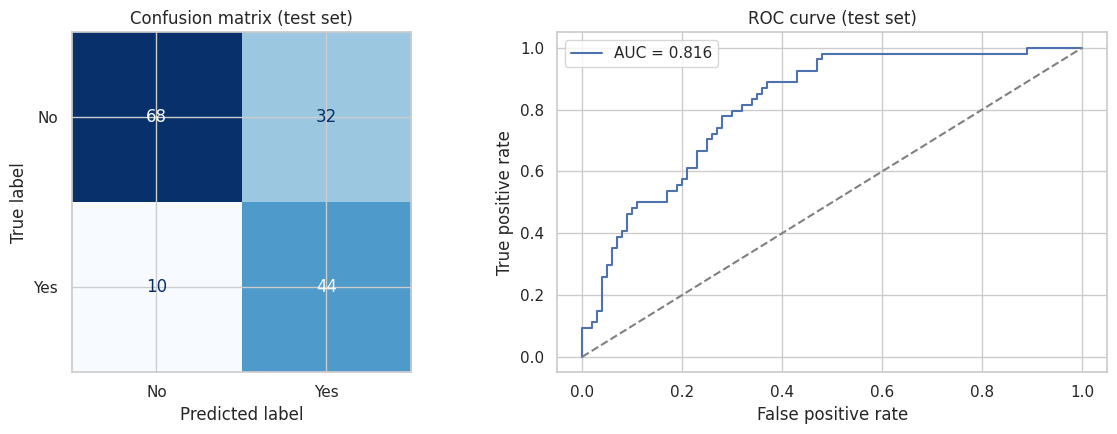

In [12]:
pred = (proba >= THRESHOLD).astype(int)
print(classification_report(y_test, pred, target_names=["No diabetes", "Diabetes"]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["No", "Yes"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion matrix (test set)")
fpr, tpr, _ = roc_curve(y_test, proba)
axes[1].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, proba):.3f}")
axes[1].plot([0, 1], [0, 1], "--", color="gray"); axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC curve (test set)"); axes[1].legend()
plt.tight_layout(); plt.savefig("images/evaluation.png", dpi=120, bbox_inches="tight"); plt.show()

### Error analysis

In [13]:
res = X_test.copy(); res["actual"] = y_test.values; res["pred"] = pred; res["proba"] = proba
res["outcome"] = np.select(
    [(res.actual == 1) & (res.pred == 1), (res.actual == 1) & (res.pred == 0),
     (res.actual == 0) & (res.pred == 1)], ["True positive", "FALSE NEGATIVE (missed)", "False positive"], "True negative")
display(res["outcome"].value_counts().to_frame("count"))
# medians computed after treating impossible zeros as missing
res_clean = zeros_to_nan(res[FEATURES]).assign(outcome=res["outcome"].values, proba=res["proba"].values)
display(res_clean.groupby("outcome")[["Glucose", "BMI", "Age", "Insulin", "proba"]].median().round(2))

,count
outcome,
True negative,68
True positive,44
False positive,32
FALSE NEGATIVE (missed),10


,Glucose,BMI,Age,Insulin,proba
outcome,,,,,
FALSE NEGATIVE (missed),113.5,30.30,28.5,101.5,0.29
False positive,137.0,36.15,29.0,194.0,0.69
True negative,99.0,26.70,24.0,93.0,0.17
True positive,144.5,34.55,38.0,184.0,0.80


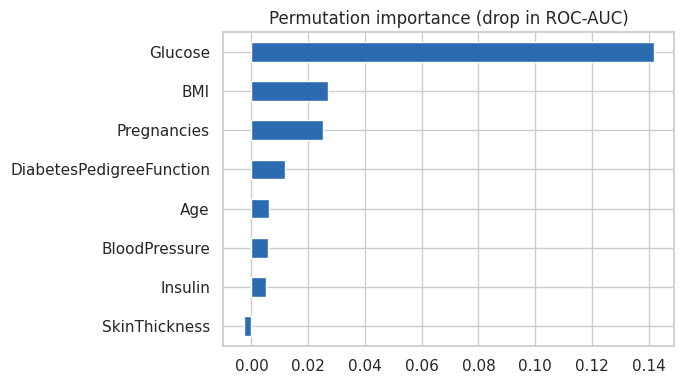

,importance
Glucose,0.142
BMI,0.027
Pregnancies,0.025
DiabetesPedigreeFunction,0.012
Age,0.006
BloodPressure,0.006
Insulin,0.005
SkinThickness,-0.003


In [14]:
# Which features drive the model? (permutation importance on the test set)
pi = permutation_importance(best_pipe, X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=RANDOM_STATE)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
imp.plot.barh(color="#2b6cb0", figsize=(7, 4)); plt.title("Permutation importance (drop in ROC-AUC)")
plt.tight_layout(); plt.savefig("images/importance.png", dpi=120, bbox_inches="tight"); plt.show()
imp.sort_values(ascending=False).round(3).to_frame("importance")

In [15]:
for t in (0.50, THRESHOLD):
    p = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    print(f"threshold {t:.2f}: caught {tp} of {tp+fn} diabetic cases | missed {fn} | false alarms {fp} | correct negatives {tn}")

threshold 0.50: caught 37 of 54 diabetic cases | missed 17 | false alarms 25 | correct negatives 75
threshold 0.43: caught 44 of 54 diabetic cases | missed 10 | false alarms 32 | correct negatives 68


## 8 · Save the final pipeline for the web app

In [16]:
# Refit the selected pipeline on ALL data would change the evaluated model, so we ship the one we evaluated.
joblib.dump({"pipeline": best_pipe, "threshold": THRESHOLD, "model_name": best_name}, "models/diabetes_pipeline.joblib")
metrics = final.iloc[2].to_dict()
json.dump({"model": best_name, "threshold": THRESHOLD, "test_metrics": metrics,
           "test_baseline": final.iloc[0].to_dict()}, open("models/metrics.json", "w"), indent=2)
print("Saved models/diabetes_pipeline.joblib")

Saved models/diabetes_pipeline.joblib


## 9 · Business insight, recommendation & limitations

**What we built:** a Logistic Regression pipeline (selected by cross-validated ROC-AUC among three tuned algorithms) with a decision threshold chosen on training data so that it catches at least 80% of diabetic cases.

**Results on the untouched test set (154 people):**
- Baseline ("nobody has diabetes"): 64.9% accuracy but **0% recall**, so it is useless for screening.
- Our model at the tuned threshold: **81.5% recall** (44 of 54 diabetic people flagged), 57.9% precision, ROC-AUC 0.816.
- Moving from the default 0.50 threshold to the tuned threshold raised recall from 68.5% to 81.5%, at the cost of more false alarms (see the threshold table above).

**Recommendation for the clinic:** use the tool as a *first-line screening filter*, not a diagnosis. People it flags should get a confirmatory lab test; roughly 4 in 10 flagged people will not have diabetes, which is an acceptable cost for catching most real cases. **Glucose** is by far the most important input (permutation importance), so ensuring a reliable glucose measurement matters most.

**Limitations**
- Small dataset (768 people; only 154 in the test set), so every test metric is noisy: expect roughly ±5 to 7 points of uncertainty.
- Only women of Pima Indian heritage aged 21+. The model should **not** be assumed to generalize to men, other populations or children.
- About half of the Insulin values were missing and imputed with the median, so Insulin and SkinThickness carry little reliable information.
- The 10 missed cases (false negatives) tend to have glucose close to healthy values; a screening tool will always miss some people, so a negative result is not a clean bill of health.
- This is an educational project, **not a medical device**.